In [1]:
!pip install pingouin


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg

from IPython.display import display

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 120

In [3]:
df = pd.read_csv("../Data/responses_completo.tsv", sep="\t")


#EDA

In [4]:
variables = [
    "disfrute",
    "competencia",
    "dificultad",
    "ajuste_reto",
    "variedad",
    "rejugar"
]

nombres_variables = {
    "disfrute": "Disfrute",
    "competencia": "Competencia percibida",
    "dificultad": "Dificultad percibida",
    "ajuste_reto": "Ajuste del reto",
    "variedad": "Variedad",
    "rejugar": "Intención de rejugar"
}

condiciones = {
    "H": "Humano",
    "N": "LLM sin telemetría",
    "P": "LLM con telemetría"
}

df["condicion"] = df["level_type"].map(condiciones)

orden = [
    "Humano",
    "LLM sin telemetría",
    "LLM con telemetría"
]

df_promedios = (
    df.groupby(["id", "condicion"], as_index=False)[variables]
      .mean()
)

display(df_promedios.head())

,id,condicion,disfrute,competencia,dificultad,ajuste_reto,variedad,rejugar
0,20261020_130429_S2,Humano,1.0,2.5,-1.5,1.0,1.0,1.0
1,20261020_130429_S2,LLM con telemetría,0.0,0.5,1.5,0.5,2.0,1.0
2,20261020_130429_S2,LLM sin telemetría,-2.5,-2.0,2.5,-2.5,-2.5,-2.5
3,20261020_130434_S5,Humano,0.5,-0.5,-0.5,1.5,0.5,-0.5
4,20261020_130434_S5,LLM con telemetría,0.5,0.0,0.5,2.0,1.5,2.0


In [5]:
estadisticas = (
    df.groupby("condicion")[variables]
      .agg(["mean", "median", "std", "min", "max"])
      .round(3)
)

display(estadisticas)

disfrute                       competencia                \
                       mean median    std min max        mean median    std   
condicion                                                                     
Humano                1.333    1.0  1.239  -3   3       1.542    1.0  1.215   
LLM con telemetría   -0.042    0.5  1.989  -3   3      -0.208   -0.5  2.105   
LLM sin telemetría    0.208    1.0  2.021  -3   3      -0.125    0.5  2.173   

                            ... variedad                       rejugar         \
                   min max  ...     mean median    std min max    mean median   
condicion                   ...                                                 
Humano              -1   3  ...    1.083    1.0  1.381  -3   3   1.292    1.0   
LLM con telemetría  -3   3  ...    0.000    1.0  2.043  -3   3  -0.167    1.0   
LLM sin telemetría  -3   3  ...    0.500    1.5  2.147  -3   3   0.167    1.0   

                                   
                      std min max  
condicion                          
Humano              1.459  -3   3  
LLM con telemetría  2.239  -3   3  
LLM sin telemetría  1.810  -3   3  

[3 rows x 30 columns]

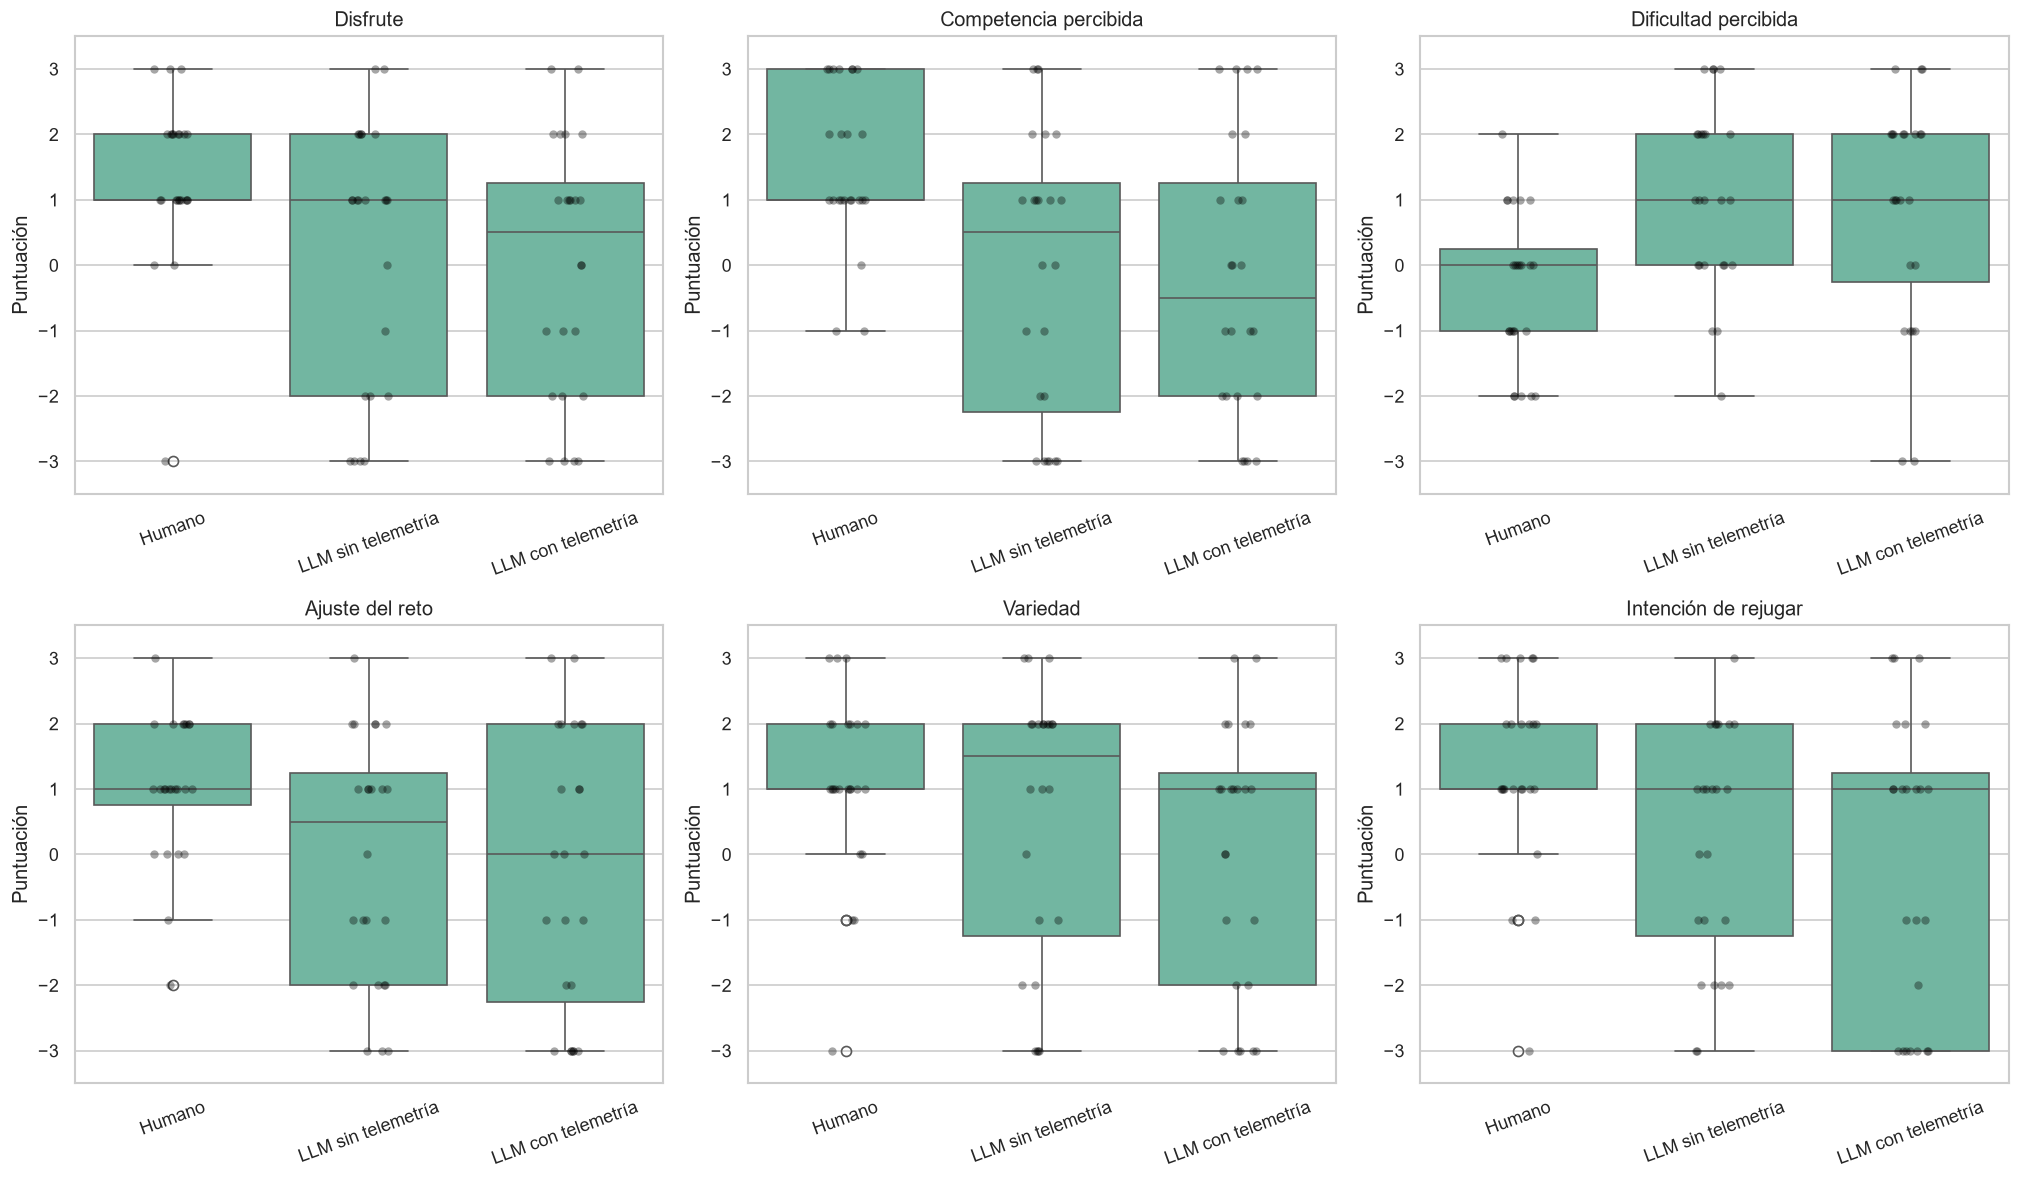

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):
    sns.boxplot(
        data=df,
        x="condicion",
        y=variable,
        order=orden,
        ax=ax
    )

    sns.stripplot(
        data=df,
        x="condicion",
        y=variable,
        order=orden,
        color="black",
        alpha=0.35,
        jitter=True,
        ax=ax
    )

    ax.set_title(nombres_variables[variable])
    ax.set_xlabel("")
    ax.set_ylabel("Puntuación")
    ax.set_ylim(-3.5, 3.5)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

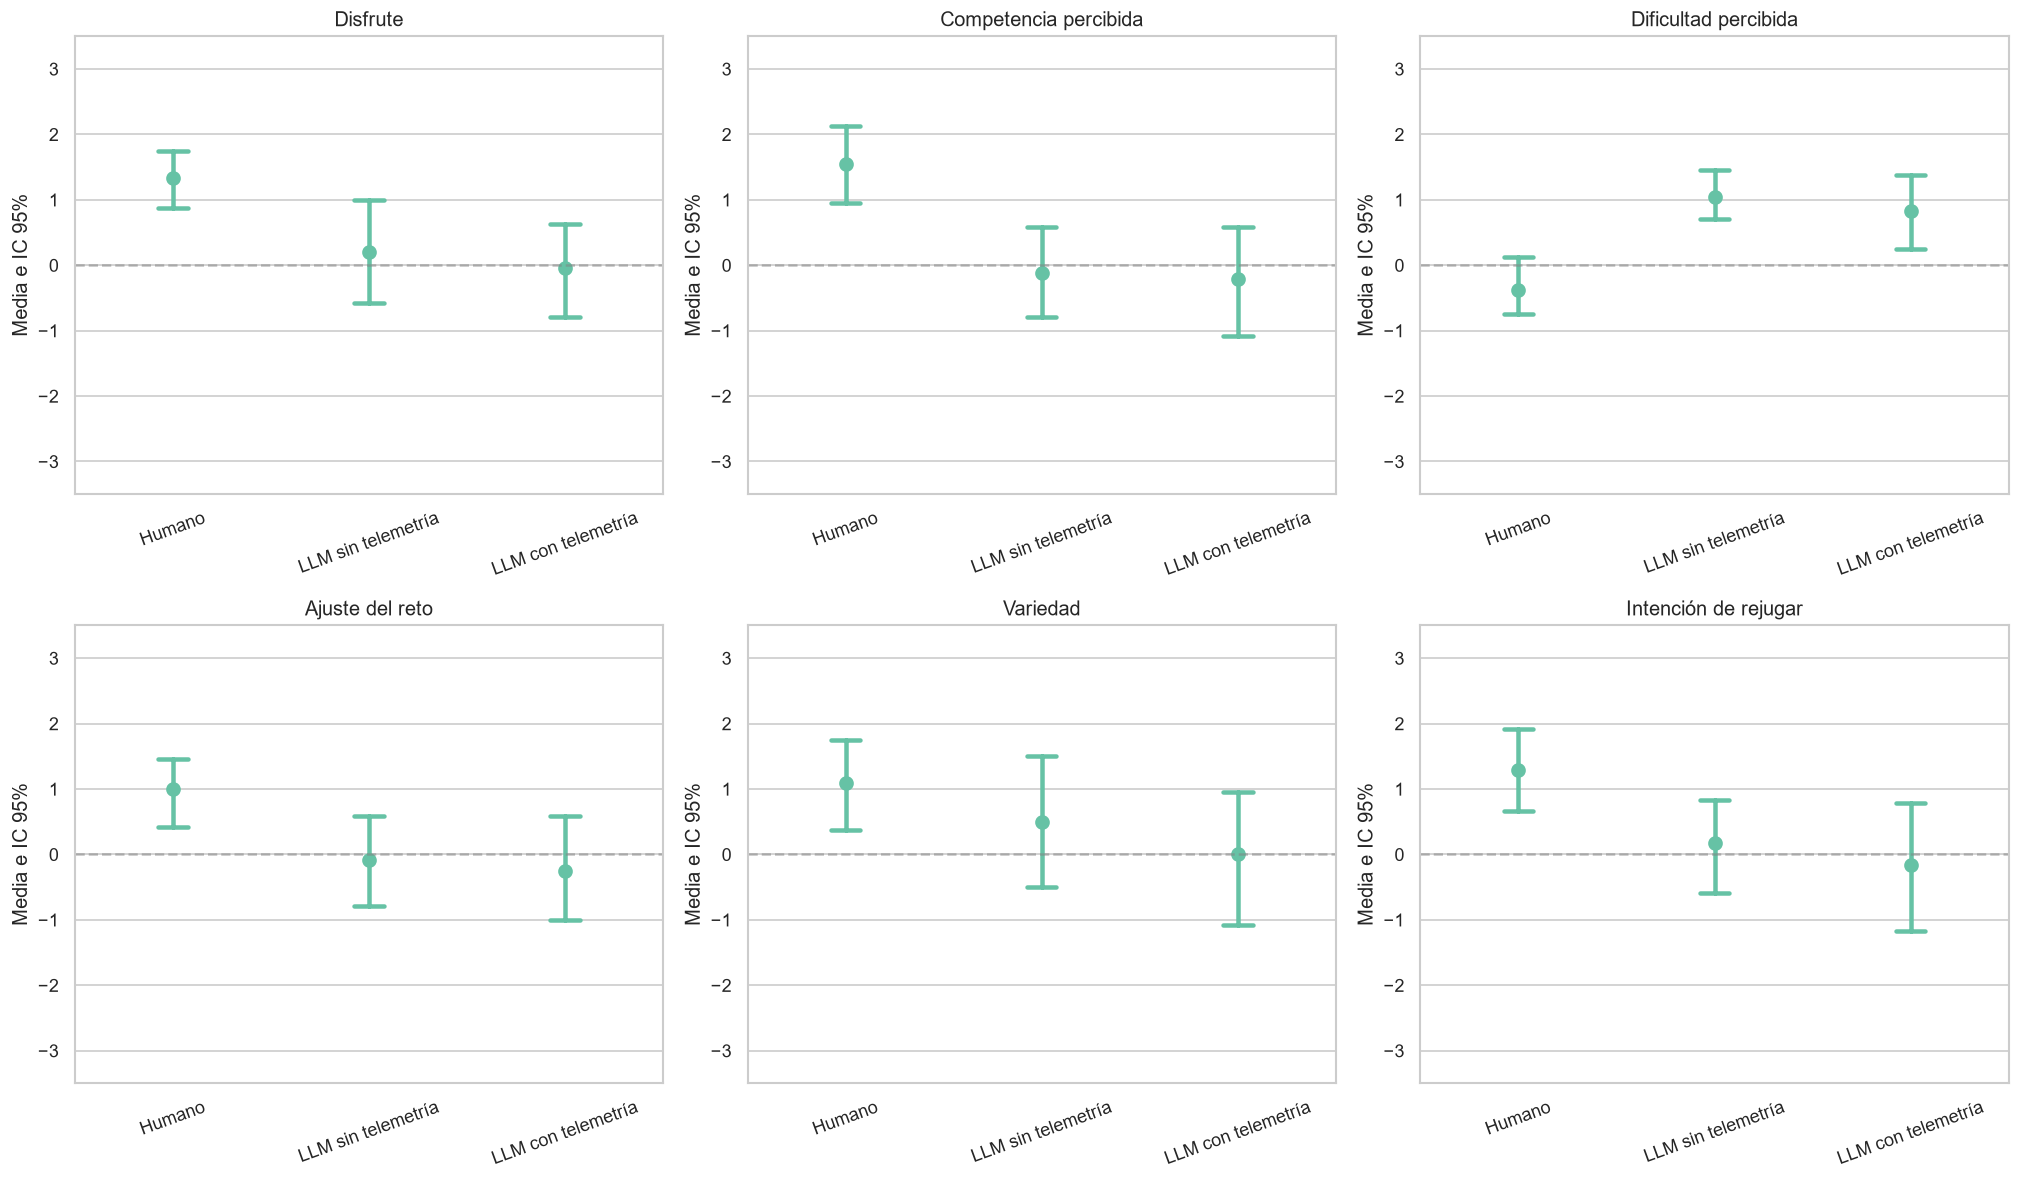

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):
    sns.pointplot(
        data=df_promedios,
        x="condicion",
        y=variable,
        order=orden,
        errorbar=("ci", 95),
        capsize=0.15,
        markers="o",
        linestyles="none",
        ax=ax
    )

    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
    ax.set_title(nombres_variables[variable])
    ax.set_xlabel("")
    ax.set_ylabel("Media e IC 95%")
    ax.set_ylim(-3.5, 3.5)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

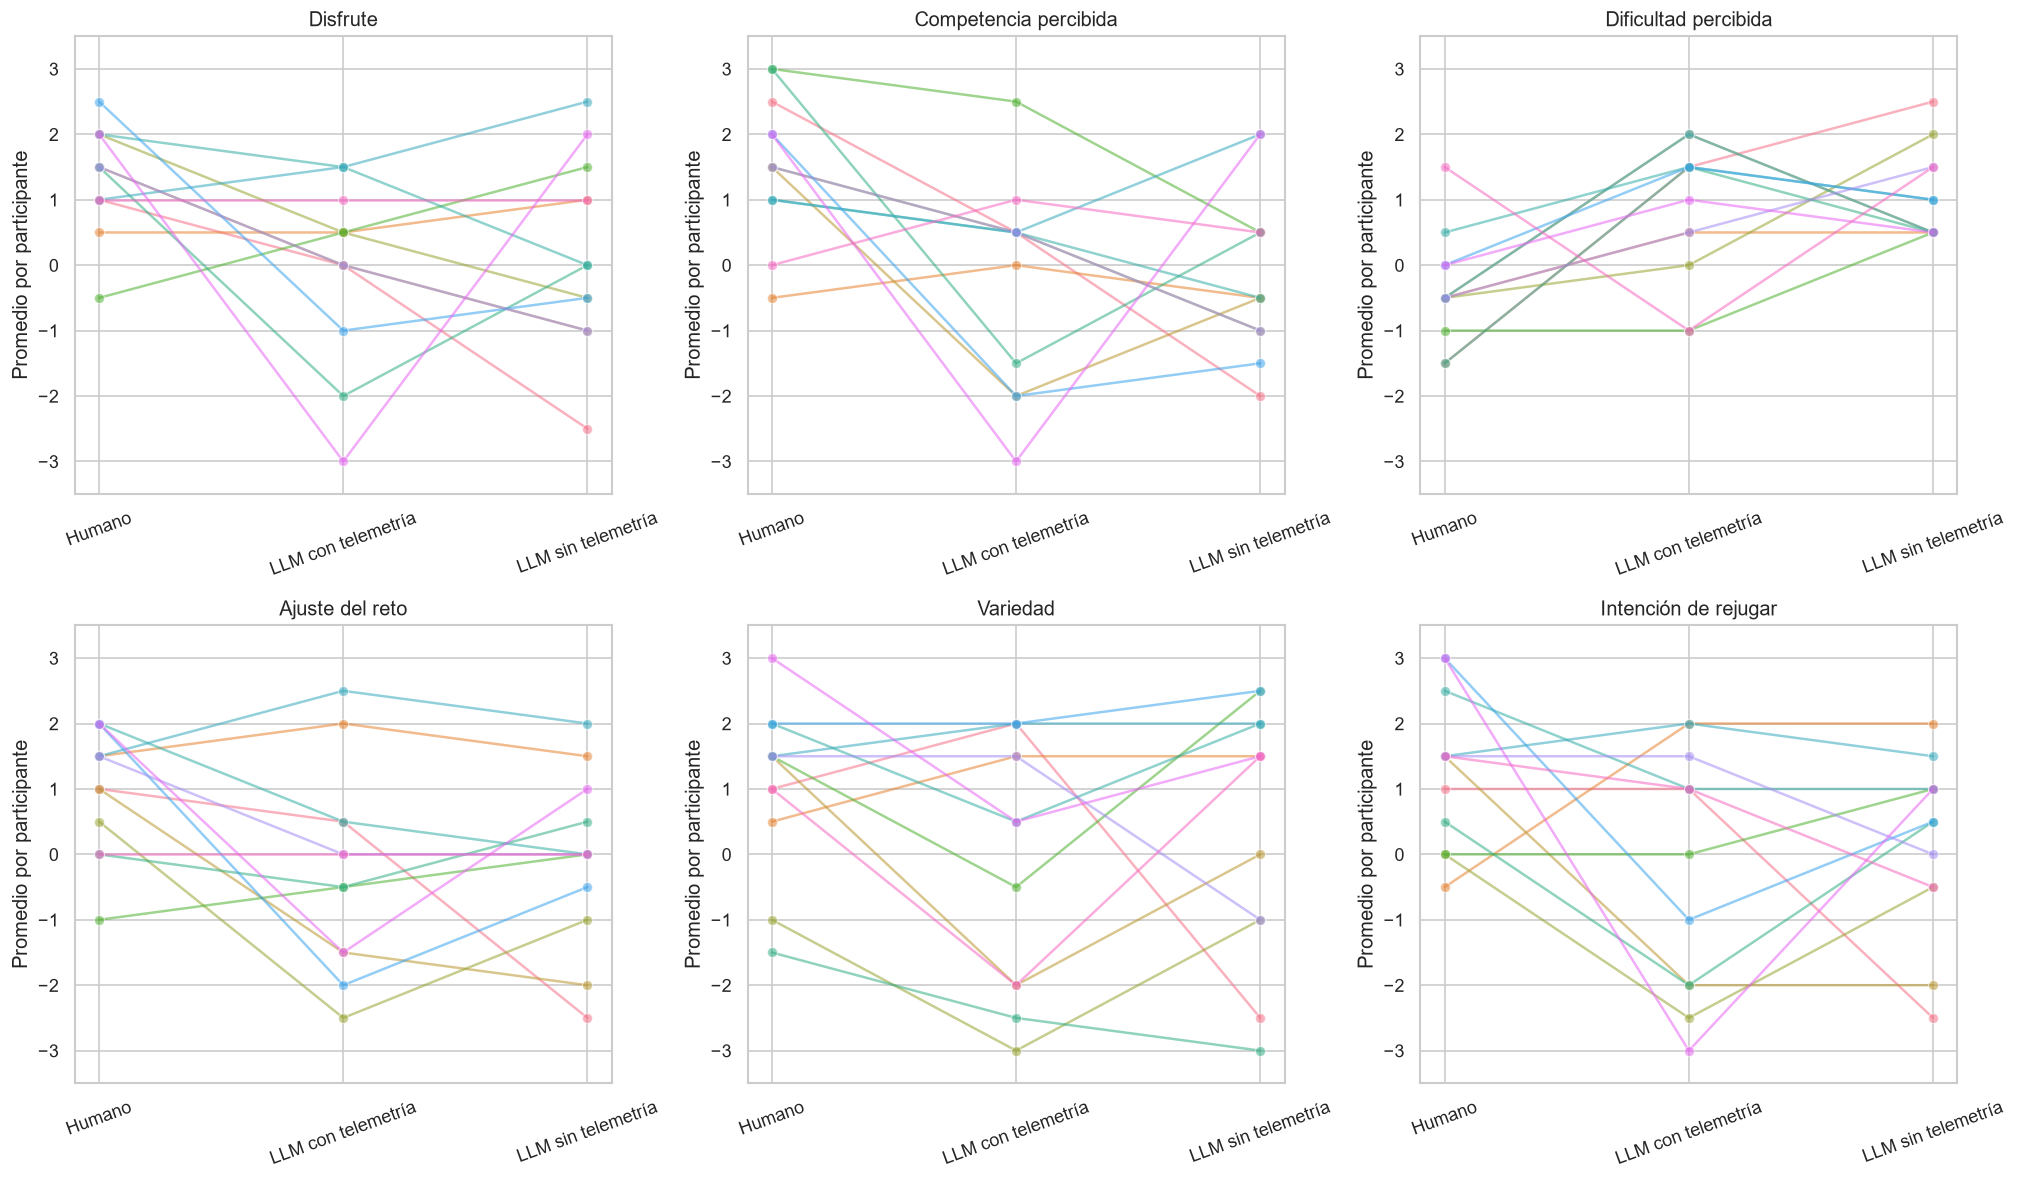

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):

    sns.lineplot(
        data=df_promedios,
        x="condicion",
        y=variable,
        hue="id",
        units="id",
        estimator=None,
        marker="o",
        alpha=0.55,
        legend=False,
        sort=False,
        ax=ax
    )

    ax.set_title(nombres_variables[variable])
    ax.set_xlabel("")
    ax.set_ylabel("Promedio por participante")
    ax.set_ylim(-3.5, 3.5)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

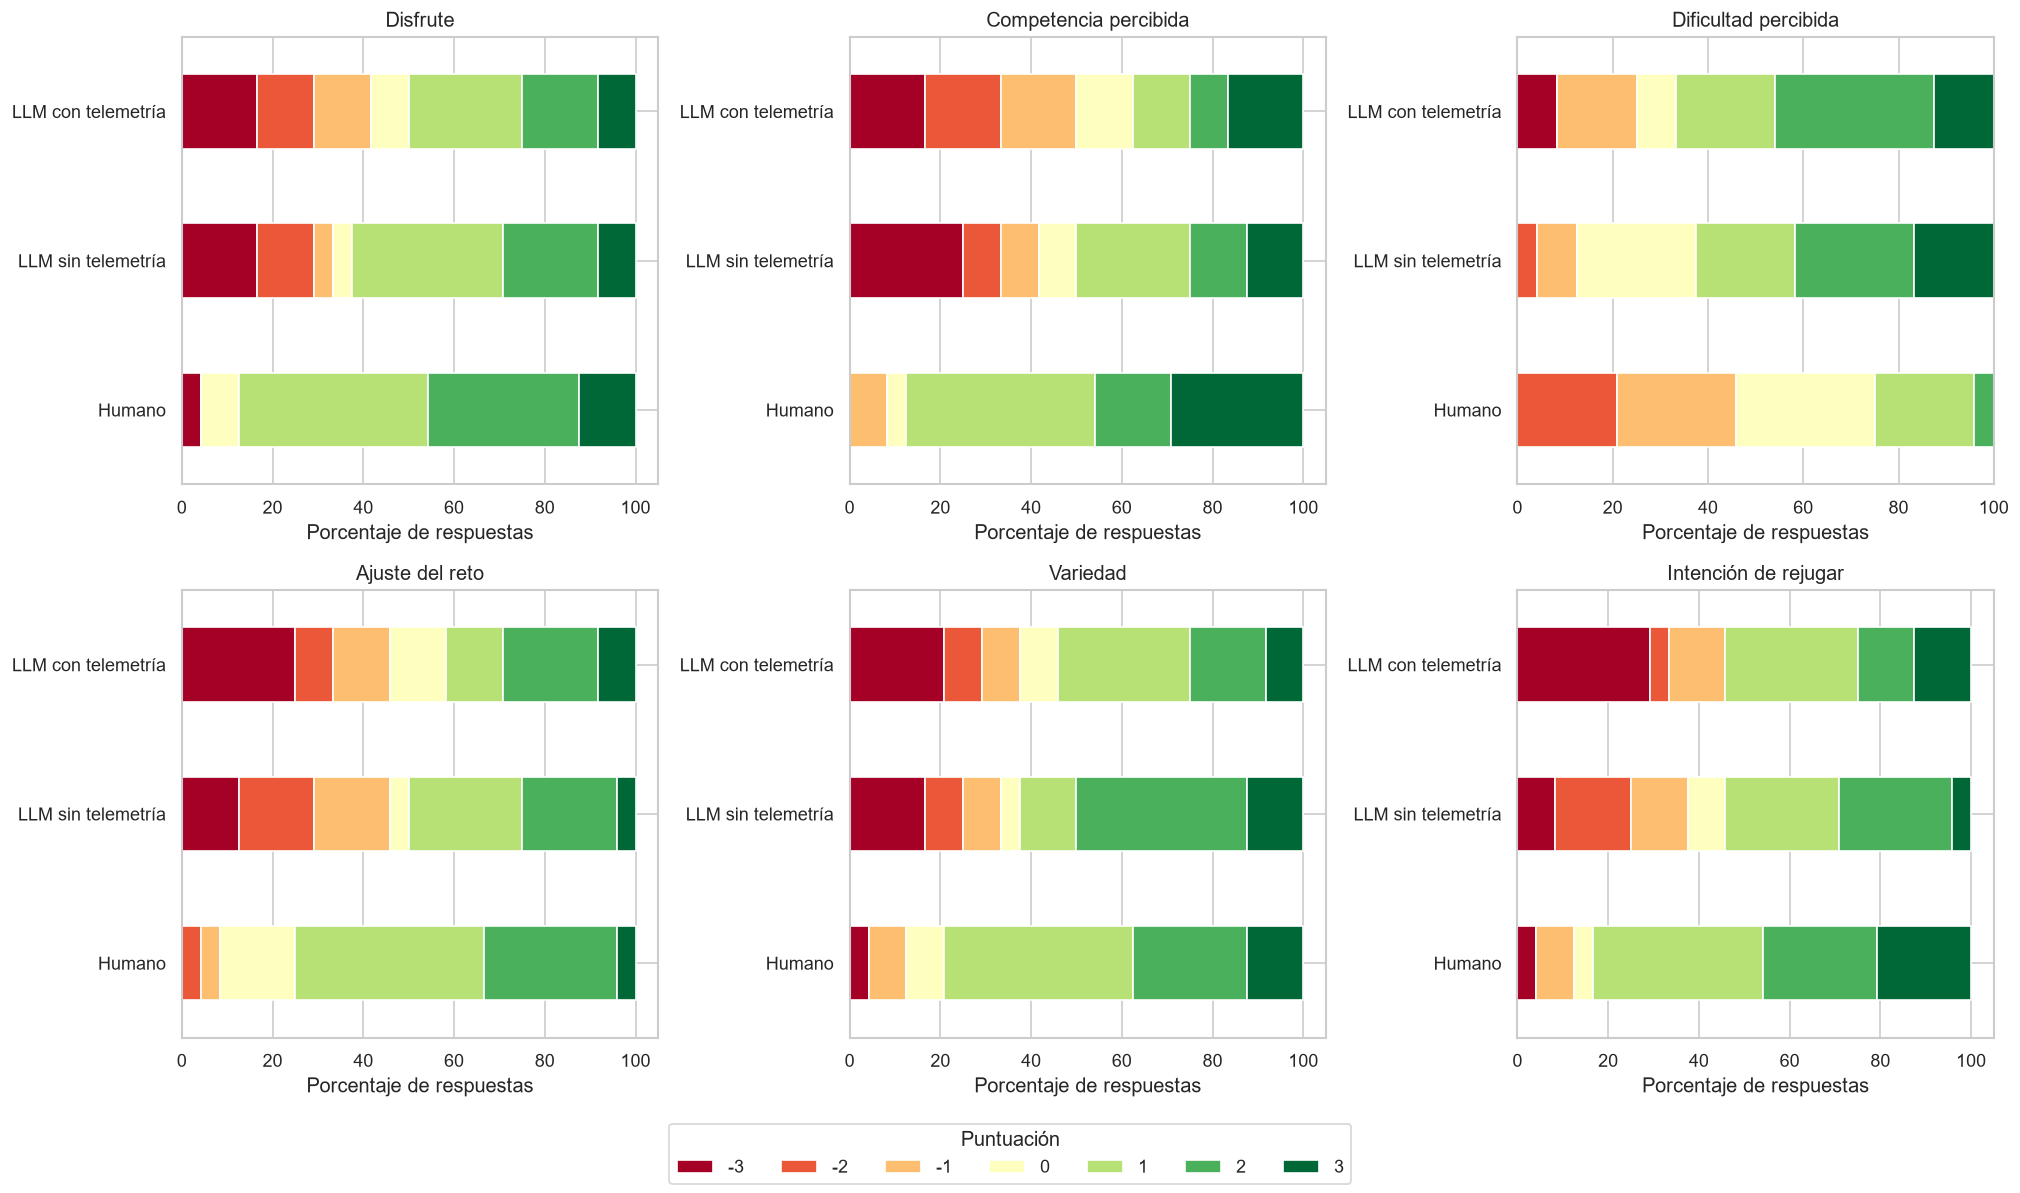

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, variable in zip(axes.flat, variables):

    tabla = pd.crosstab(
        df["condicion"],
        df[variable],
        normalize="index"
    ) * 100

    tabla = tabla.reindex(
        index=orden,
        columns=range(-3, 4),
        fill_value=0
    )

    tabla.plot(
        kind="barh",
        stacked=True,
        ax=ax,
        colormap="RdYlGn",
        legend=False
    )

    ax.set_title(nombres_variables[variable])
    ax.set_xlabel("Porcentaje de respuestas")
    ax.set_ylabel("")

handles, labels = axes.flat[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Puntuación",
    loc="lower center",
    ncol=7
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

## Prueba de normalidad (Shapiro-Wilk)

Antes de elegir/afinar el modelo estadístico conviene revisar si, dentro de
cada condición, la distribución de cada variable se aproxima a una normal.
Se usa la prueba de **Shapiro-Wilk** (`pg.normality`), aplicada sobre las
**72 observaciones individuales** (`df`: las 2 repeticiones de cada
condición sin promediar), ya que el modelo de efectos mixtos usará esas
observaciones completas (con `id` como efecto aleatorio) en lugar de
promediarlas por participante. Promediar antes de evaluar normalidad
reduciría artificialmente la varianza y podría cambiar la conclusión de la
prueba (el mismo problema que ya se identificó para el ANOVA promediado).

H0: los datos de ese grupo provienen de una distribución normal.
Un p-valor < 0.05 indica evidencia de que NO son normales.

In [10]:
resultados_normalidad = []

for variable in variables:

    normalidad = pg.normality(
        data=df,
        dv=variable,
        group="condicion"
    ).reset_index().rename(columns={"index": "condicion"})

    normalidad["Variable"] = nombres_variables[variable]

    resultados_normalidad.append(normalidad)

tabla_normalidad = pd.concat(resultados_normalidad, ignore_index=True)

tabla_normalidad["Normal (Shapiro-Wilk)"] = tabla_normalidad["normal"].map(
    {True: "Sí", False: "No"}
)

columnas_normalidad = [
    "Variable",
    "condicion",
    "W",
    "pval",
    "Normal (Shapiro-Wilk)"
]

display(
    tabla_normalidad[columnas_normalidad]
        .rename(columns={"condicion": "Condición", "pval": "p-valor"})
        .round(4)
)

n_no_normales = (tabla_normalidad["normal"] == False).sum()
print(f"\nGrupos (variable x condición) que no pasan Shapiro-Wilk (p < 0.05): {n_no_normales} de {len(tabla_normalidad)}")

,Variable,Condición,W,p-valor,Normal (Shapiro-Wilk)
0,Disfrute,LLM sin telemetría,0.8641,0.0040,No
1,Disfrute,LLM con telemetría,0.9130,0.0411,No
2,Disfrute,Humano,0.8016,0.0003,No
3,Competencia percibida,LLM sin telemetría,0.8841,0.0100,No
4,Competencia percibida,LLM con telemetría,0.9092,0.0339,No
5,Competencia percibida,Humano,0.8620,0.0037,No
6,Dificultad percibida,LLM sin telemetría,0.9315,0.1050,Sí
7,Dificultad percibida,LLM con telemetría,0.8848,0.0104,No
8,Dificultad percibida,Humano,0.9111,0.0373,No
9,Ajuste del reto,LLM sin telemetría,0.9075,0.0312,No



Grupos (variable x condición) que no pasan Shapiro-Wilk (p < 0.05): 17 de 18


## Modelo Lineal de Efectos Mixtos (LMM)

### Etapa 1: Preparación de datos

El LMM se ajusta sobre `df`, es decir, las **72 observaciones individuales**
(12 participantes × 3 condiciones × 2 repeticiones), **sin promediar** por
participante y condición. A diferencia del ANOVA de medidas repetidas, el
LMM puede usar todas las observaciones directamente porque modela la
correlación entre observaciones del mismo participante a través de un
**efecto aleatorio por `id`**, en lugar de requerir una sola fila por
sujeto/condición.

Antes de ajustar cualquier modelo, dejamos preparado lo siguiente:

1. **Nivel de referencia**: fijamos `"Humano"` como condición base de
   `condicion` (equivalente a `level_type == "H"`), ya que es el control
   natural del experimento. Así, los coeficientes del modelo se interpretan
   directamente como la diferencia de cada condición LLM respecto a jugar
   contra un nivel diseñado por una persona.
2. **Valores faltantes**: verificamos que no haya nulos en `id`, `condicion`
   ni en las 6 variables de respuesta.
3. **Balance de observaciones**: confirmamos cuántas filas hay por cada
   combinación de `id` x `condicion` (se espera 2, una por repetición). El
   LMM no requiere este balance perfecto para funcionar, pero es una buena
   verificación de que los datos están completos antes de modelar.

In [11]:
import statsmodels.formula.api as smf

df["condicion"] = pd.Categorical(
    df["condicion"],
    categories=["Humano", "LLM sin telemetría", "LLM con telemetría"],
    ordered=False
)

print("Categorías de 'condicion' (la primera es la referencia):")
print(df["condicion"].cat.categories.tolist())

columnas_clave = ["id", "condicion"] + variables
nulos = df[columnas_clave].isna().sum()

print("\nValores faltantes por columna:")
display(nulos.to_frame("nulos"))

conteo_obs = (
    df.groupby(["id", "condicion"], observed=True)
      .size()
      .reset_index(name="n_observaciones")
)

print("\nResumen de observaciones por participante x condición:")
display(conteo_obs["n_observaciones"].value_counts().to_frame("n_combinaciones id x condicion"))

combinaciones_incompletas = conteo_obs[conteo_obs["n_observaciones"] != 2]
if len(combinaciones_incompletas) == 0:
    print("\nTodas las combinaciones id x condición tienen exactamente 2 observaciones (sin datos faltantes).")
else:
    print("\nCombinaciones con un número de observaciones distinto de 2:")
    display(combinaciones_incompletas)

Categorías de 'condicion' (la primera es la referencia):
['Humano', 'LLM sin telemetría', 'LLM con telemetría']

Valores faltantes por columna:


,nulos
id,0
condicion,0
disfrute,0
competencia,0
dificultad,0
ajuste_reto,0
variedad,0
rejugar,0



Resumen de observaciones por participante x condición:


,n_combinaciones id x condicion
n_observaciones,
2,36



Todas las combinaciones id x condición tienen exactamente 2 observaciones (sin datos faltantes).
